# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Кривичко Назар'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 11      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 11: Рівне, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx', 'pyrosm']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.1.4


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_рівне


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT
ox.settings.overpass_url = 'https://overpass-api.de/api/interpreter'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def retry(fn, tries=6, wait=20):
    """Повтор із подвоєнням паузи: 20 → 40 → 80 → 160 → 320 с."""
    for i in range(tries):
        try:
            return fn()
        except Exception as e:
            if i == tries - 1:
                raise
            print('спроба %d не вдалась (%s), чекаю %d с' % (i + 1, type(e).__name__, wait))
            time.sleep(wait)
            wait *= 2


def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    t0, b0 = time.time(), cache_bytes()
    g = retry(getter)
    if g.empty:
        COST[name] = {'спосіб': 'живий запит', 'записів': 0,
                      'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                      'файл_МБ': 0.0, 'секунд': round(time.time() - t0, 1)}
        return g
    clean(g).to_parquet(path, index=False)
    g = gpd.read_parquet(path)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return g

In [7]:
boundary  = fetch('boundary',  lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
heritage  = fetch('heritage',  lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations  = fetch('stations',  lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))
print('heritage %d | stations %d | amenities %d'
      % (len(heritage), len(stations), len(amenities)))


heritage 119 | stations 5 | amenities 235


In [8]:
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    print('→ мережа зі знімка ...', flush=True)
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    from pyrosm import OSM, get_data
    print('→ мережа walk з офлайн-витягу PBF (Overpass недоступний)', flush=True)
    print('  старт о %s' % time.strftime('%H:%M:%S'), flush=True)
    t0 = time.time()

    fp = get_data('ukraine', directory=OUT)
    pbf_mb = os.path.getsize(fp) / 1e6
    print('  витяг: %.0f МБ, за %.1f с' % (pbf_mb, time.time() - t0), flush=True)

    print('  читаю мережу в межах міста ...', flush=True)
    osm = OSM(fp, bounding_box=poly)
    nodes_p, edges_p = osm.get_network(network_type='walking', nodes=True)
    print('  прочитано: %d вузлів, %d ребер' % (len(nodes_p), len(edges_p)), flush=True)

    nodes = gpd.GeoDataFrame({'osmid': nodes_p['id'].astype('int64'),
                              'x': nodes_p['lon'].astype(float),
                              'y': nodes_p['lat'].astype(float)},
                             geometry=nodes_p.geometry, crs='EPSG:4326')
    edges = edges_p.rename(columns={'u': 'u', 'v': 'v', 'length': 'length'})
    if 'length' not in edges.columns:
        edges['length'] = edges.to_crs(32635).length
    edges = gpd.GeoDataFrame(
        {'u': edges['u'].astype('int64'), 'v': edges['v'].astype('int64'),
         'length': edges['length'].astype(float)},
        geometry=edges.geometry, crs='EPSG:4326')

    print('  зберігаю ...', flush=True)
    nodes.to_parquet(NODES_P, index=False)
    edges.to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'офлайн PBF', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round(pbf_mb, 1),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('✓ вузлів %d | ребер %d' % (len(nodes), len(edges)), flush=True)

→ мережа зі знімка ...
✓ вузлів 26356 | ребер 30023


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
df = pd.DataFrame(COST).T
display(df)
print('усього передано мережею: %.2f МБ' % df['передано_МБ'].sum())
print('усього часу: %.1f с' % df['секунд'].sum())
import glob
print('кеш Overpass (що приїхало мережею): %.2f МБ' % (cache_bytes() / 1e6))
print('знімки .parquet (що лежить на диску): %.2f МБ'
      % (sum(os.path.getsize(f) for f in glob.glob(os.path.join(OUT, '*.parquet'))) / 1e6))

# Живе завантаження всіх шарів зайняло 182.9 с, з них 182.8 с — мережа пішоходів. Читання тих самих даних зі знімка займає 0.086 с (сума по чотирьох шарах) плюс ~0.1 с на мережу, тобто близько 0.19 с. Прискорення — приблизно у 960 разів.

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.028,0.34
heritage,знімок,119,0.0,0.061,0.057
stations,знімок,5,0.0,0.032,0.066
amenities,знімок,235,0.0,0.057,0.036
мережа walk,знімок,56379,0.0,2.352,0.061


усього передано мережею: 0.00 МБ
усього часу: 0.6 с
кеш Overpass (що приїхало мережею): 0.26 МБ
знімки .parquet (що лежить на диску): 2.53 МБ


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
mask = heritage['historic'].notna() | heritage['tourism'].isin(TOURISM_OK)
by_tag = heritage[mask]
cand = by_tag[by_tag['name'].notna()].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', len(by_tag))
print('з них мають name       :', len(cand))
print('відкинуто без назви    :', len(by_tag) - len(cand))

усього у шарі heritage : 119
підходять за тегами    : 119
з них мають name       : 105
відкинуто без назви    : 14


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial               49
monument                5
tank                    3
cannon                  3
archaeological_site     2
vehicle                 2
building                1
aircraft                1
city_gate               1

=== tourism ===
tourism
artwork       24
attraction     9
museum         3
gallery        2
viewpoint      1

типи геометрії: {'Point': 101, 'Polygon': 4}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [12]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

wiki_cols = [c for c in cand.columns if c in ('wikidata', 'wikipedia')]
cand['wiki'] = cand[wiki_cols].notna().any(axis=1).astype(int) if wiki_cols else 0

lang_cols = [c for c in cand.columns if c.startswith('name:')]
cand['n_lang'] = cand[lang_cols].notna().sum(axis=1) if lang_cols else 0

cand['is_museum'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)
cand['is_historic'] = cand['historic'].notna().astype(int)

cand['score'] = (0.40 * cand['wiki']
                 + 0.25 * cand['n_lang'].rank(pct=True)
                 + 0.20 * cand['is_museum']
                 + 0.10 * cand['is_historic']
                 + 0.05 * cand['area_m2'].rank(pct=True))

cand = cand.sort_values('score', ascending=False).reset_index(drop=True)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мовних назв  : медіана %.0f, максимум %d'
      % (cand['n_lang'].median(), cand['n_lang'].max()))
print()
print(cand[['name', 'wiki', 'n_lang', 'is_museum', 'score']].head(15).to_string(index=False))

кандидатів   : 105
мають wiki   : 7
мовних назв  : медіана 1, максимум 3

                                name  wiki  n_lang  is_museum    score
      Загиблим у війні 1941-1945 рр.     1       1          0 0.642143
      Марії Несвицькій (Рівненській)     1       1          0 0.642143
                     Тарасу Шевченку     1       1          0 0.642143
                        Климу Савуру     1       1          0 0.642143
                      Симону Петлюрі     1       1          0 0.642143
                               ЗіС-3     1       1          0 0.642143
         Таємничі підземелля Рівного     1       1          0 0.642143
                   Краєзнавчий музей     0       2          1 0.485238
    Літературний музей Уласа Самчука     0       3          1 0.473095
                      Музей бурштину     0       3          1 0.473095
                     Жертвам нацизму     0       2          0 0.360000
                   Володимир Мисечко     0       2          0 0.360000
Пам

### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE = 10, 30

top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
overlap   = len(set(top10['name']) & set(top_naive['name']))

print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'за площею': list(top_naive['name'])}))

перетин: 7 з 10


,за вашим критерієм,за площею
0,Загиблим у війні 1941-1945 рр.,Басівкутське городище
1,Марії Несвицькій (Рівненській),Краєзнавчий музей
2,Тарасу Шевченку,Статуя Тараса Григоровича Шевченка
3,Климу Савуру,Вхідна вежа
4,Симону Петлюрі,Загиблим у війні 1941-1945 рр.
5,ЗіС-3,Марії Несвицькій (Рівненській)
6,Таємничі підземелля Рівного,Тарасу Шевченку
7,Краєзнавчий музей,Климу Савуру
8,Літературний музей Уласа Самчука,Симону Петлюрі
9,Музей бурштину,ЗіС-3


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [14]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])


pairs = close_pairs(top_score, 60)

print('пар ближче 60 м: %d' % len(pairs))
for i, j, d in pairs:
    print('%6.1f м | %s  ↔  %s'
          % (d, top_score.loc[i, 'name'], top_score.loc[j, 'name']))
    # Видалити — одну пару. «Євро-Арт ↔ Євро-Арт», 12 м. Однакова назва, той самий об'єкт внесений двічі

пар ближче 60 м: 8
   6.2 м | Літературний музей Уласа Самчука  ↔  Музей бурштину
  11.8 м | Климу Савуру  ↔  В пам'ять про вбитих патріотів
  12.4 м | Євро-Арт  ↔  Євро-Арт
  24.3 м | Тарасу Шевченку  ↔  Таємничі підземелля Рівного
  26.2 м | Краєзнавчий музей  ↔  Меморіальна дошка митлополиту Іларіону (Іван Огієнко)
  29.9 м | ЗіС-3  ↔  Меморіальна дошка митлополиту Іларіону (Іван Огієнко)
  37.5 м | Пам'ятна дошка гетьману Івану Мазепі  ↔  Жертвам Чорнобильскої катастрофи
  56.0 м | ЗіС-3  ↔  Краєзнавчий музей


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 5
                       name  railway       building
0                    Озерна  station           <NA>
1              Партизанська  station           <NA>
2                     Рівне  station           <NA>
3                 Дворецька     halt           <NA>
4  Залізничний вокзал Рівне     <NA>  train_station


In [16]:
station = stations[stations['railway'] == 'station'].head(1)
if station.empty:
    station = stations[stations['name'].notna()].head(1)
print('старт:', station['name'].iloc[0])

старт: Озерна


In [22]:
G = nx.Graph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 26356 вузлів, 30023 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [23]:
def check_snap(points, ids, dist, label):
    k, uniq = len(ids), len(set(ids))
    print('[%s] точок %d, різних вузлів %d' % (label, k, uniq))
    print('     відстань точка → вузол: медіана %.1f м, максимум %.1f м'
          % (float(np.median(dist)), float(np.max(dist))))
    if uniq < k:
        print('     УВАГА: %d точок злиплись на спільних вузлах' % (k - uniq))
        by_node = collections.defaultdict(list)
        for name, nd in zip(points['name'], ids):
            by_node[nd].append(str(name))
        for nd, names in by_node.items():
            if len(names) > 1:
                print('       вузол %s: %s' % (nd, ' | '.join(names)))
    else:
        print('     ок: кожна точка на своєму вузлі')
    return uniq == k

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [24]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D


def straight_matrix(points):
    """Матриця прямих віддалей у метрах."""
    p = points.to_crs(32635)
    XY = np.c_[p.geometry.x.values, p.geometry.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))


def detour_factor(D, E):
    """Медіана відношення дорога / пряма, по скінченних парах."""
    m = np.isfinite(D) & (E > 0)
    return float(np.median(D[m] / E[m]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [25]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10) 
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

[мала задача] точок 11, різних вузлів 10
     відстань точка → вузол: медіана 11.9 м, максимум 25.6 м
     УВАГА: 1 точок злиплись на спільних вузлах
       вузол 6956770529: Літературний музей Уласа Самчука | Музей бурштину
матриця за 0.569 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.17


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [26]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))


def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    k = len(D)
    unvisited = set(range(1, k))
    tour, cur = [0], 0
    while unvisited:
        nxt = min(unvisited, key=lambda j: D[cur, j])
        tour.append(nxt)
        unvisited.remove(nxt)
        cur = nxt
    tour.append(0)
    return tour


def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = list(tour)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                a, b, c, d = best[i - 1], best[i], best[j], best[j + 1]
                delta = (D[a, c] + D[b, d]) - (D[a, b] + D[c, d])
                if delta < -1e-9:
                    best[i:j + 1] = best[i:j + 1][::-1]
                    improved = True
    return best

In [27]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [28]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [29]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,9557,4.38
2-opt,9167,0.12
Held-Karp (точний),9156,0.00



оптимальний порядок:
   0. СТАРТ: Озерна
   1. Краєзнавчий музей
   2. ЗіС-3
   3. Марії Несвицькій (Рівненській)
   4. Музей бурштину
   5. Літературний музей Уласа Самчука
   6. Симону Петлюрі
   7. Таємничі підземелля Рівного
   8. Тарасу Шевченку
   9. Климу Савуру
  10. Загиблим у війні 1941-1945 рр.
  11. СТАРТ: Озерна

довжина: 9.16 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [30]:
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = (2 ** (n - 1)) * (n - 1)
    rows.append({'n': n, 'клітин': cells, 'ГБ при 8 байтах': cells * 8 / 1024 ** 3})
tbl = pd.DataFrame(rows).set_index('n')
display(tbl.style.format({'клітин': '{:,.0f}', 'ГБ при 8 байтах': '{:,.2f}'}))

,клітин,ГБ при 8 байтах
n,,
11,"10,240",0.00
16,"491,520",0.00
21,"20,971,520",0.16
26,"838,860,800",6.25
31,"32,212,254,720",240.00


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [31]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

[велика задача] точок 31, різних вузлів 28
     відстань точка → вузол: медіана 13.8 м, максимум 43.5 м
     УВАГА: 3 точок злиплись на спільних вузлах
       вузол 4883483362: Климу Савуру | В пам'ять про вбитих патріотів
       вузол 6956770529: Літературний музей Уласа Самчука | Музей бурштину
       вузол 6992629151: Євро-Арт | Євро-Арт
коефіцієнт обходу: 1.20
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    22795 м
2-opt            :    20035 м  за 0.002 с  (коротше на 12.1%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м


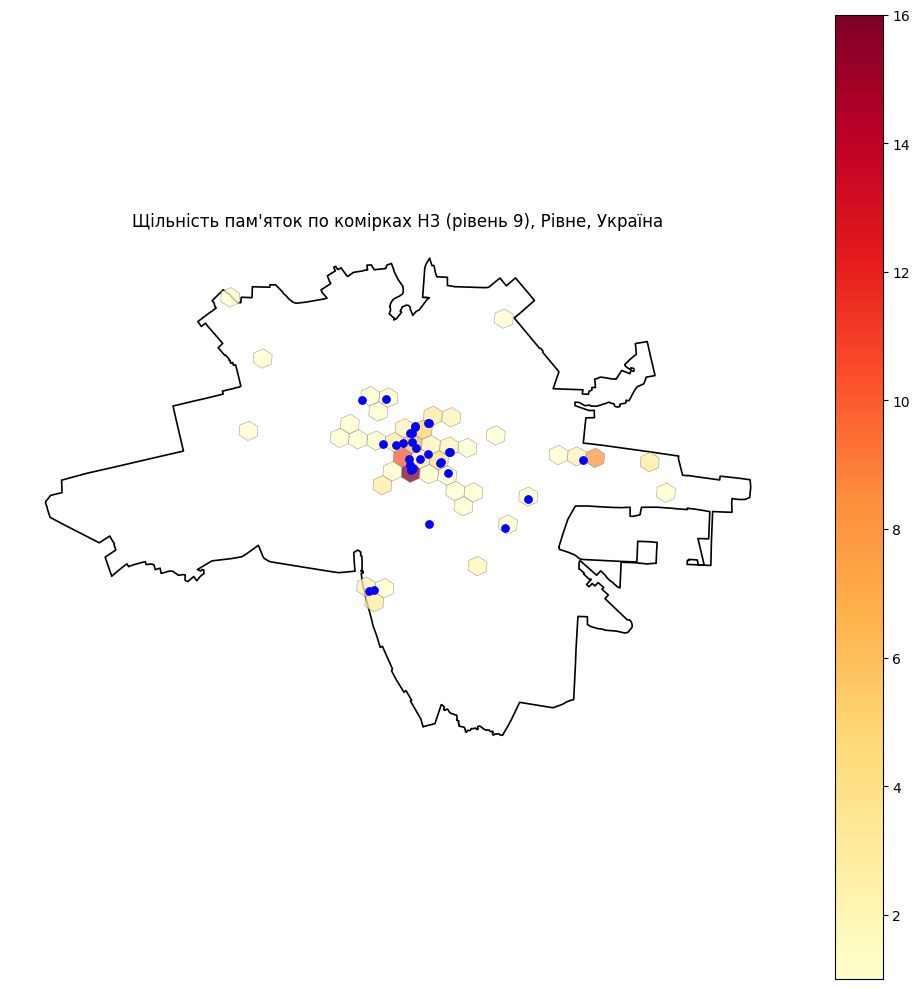


комірок усього        : 43
половина пам'яток у   : 8 комірках
найщільніша комірка   : 16 об'єктів


In [32]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

pts = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in pts]

dens = cand['h3'].value_counts()
hexes = gpd.GeoDataFrame(
    {'h3': dens.index, 'кандидатів': dens.values},
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)])
              for c in dens.index],
    crs='EPSG:4326')

fig, ax = plt.subplots(figsize=(10, 10))
boundary.boundary.plot(ax=ax, color='black', linewidth=1.2, zorder=1)
hexes.plot(ax=ax, column='кандидатів', cmap='YlOrRd', alpha=0.75,
           edgecolor='grey', linewidth=0.4, legend=True, zorder=2)
pts30.plot(ax=ax, color='blue', markersize=28, zorder=3)
ax.set_title('Щільність пам\'яток по комірках H3 (рівень %d), %s' % (H3_RES, CITY))
ax.set_axis_off()
plt.tight_layout()
plt.show()

half = (dens.cumsum() <= len(cand) / 2).sum() + 1
print()
print('комірок усього        : %d' % len(dens))
print('половина пам\'яток у   : %d комірках' % half)
print('найщільніша комірка   : %d об\'єктів' % dens.iloc[0])

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [33]:
pts_m = pts30.to_crs(32635)
am_m = amenities.copy()
am_m['geometry'] = am_m.geometry.representative_point()
am_m = am_m.to_crs(32635)[['name', 'amenity', 'geometry']].rename(
    columns={'name': 'заклад'})

near = gpd.sjoin_nearest(pts_m, am_m, how='left', distance_col='відстань_м')
near = near.drop_duplicates(subset='name').reset_index(drop=True)

tbl = near[['name', 'заклад', 'amenity', 'відстань_м']].copy()
tbl['відстань_м'] = tbl['відстань_м'].round(0)
display(tbl)

print()
print('медіана відстані до найближчого закладу: %.0f м' % tbl['відстань_м'].median())
print('максимум: %.0f м (%s)'
      % (tbl['відстань_м'].max(), tbl.loc[tbl['відстань_м'].idxmax(), 'name']))

,name,заклад,amenity,відстань_м
0,СТАРТ: Озерна,<NA>,cafe,181.0
1,Загиблим у війні 1941-1945 рр.,Фламінго,restaurant,55.0
2,Марії Несвицькій (Рівненській),Автомат питної води,drinking_water,36.0
3,Тарасу Шевченку,Шахівка,cafe,48.0
4,Климу Савуру,У Тьоті Рози,cafe,35.0
5,Симону Петлюрі,"Мила, це я",cafe,42.0
6,ЗіС-3,DarkSide2,cafe,42.0
7,Таємничі підземелля Рівного,Шахівка,cafe,44.0
8,Краєзнавчий музей,DarkSide2,cafe,97.0
9,Літературний музей Уласа Самчука,Celentano,restaurant,99.0



медіана відстані до найближчого закладу: 70 м
максимум: 324 м (Меморіал Слави)


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [35]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords


real = route_coords(ex10, ids10)
direct = [(float(pts10.geometry.y.iloc[i]), float(pts10.geometry.x.iloc[i])) for i in ex10]

centre = [float(np.mean([c[0] for c in real])), float(np.mean([c[1] for c in real]))]
fmap = folium.Map(location=centre, zoom_start=14, tiles=BASEMAP)

folium.PolyLine(direct, color='#d62728', weight=2, opacity=0.8, dash_array='6,6',
                tooltip='прямі відрізки між точками').add_to(fmap)
folium.PolyLine(real, color='#1f77b4', weight=4, opacity=0.9,
                tooltip='маршрут по ребрах графа').add_to(fmap)

for step, i in enumerate(ex10[:-1]):
    lat = float(pts10.geometry.y.iloc[i])
    lon = float(pts10.geometry.x.iloc[i])
    name = str(pts10['name'].iloc[i])
    folium.Marker(
        [lat, lon],
        tooltip='%d. %s' % (step, name),
        icon=folium.DivIcon(html=(
                '<div style="background:%s;color:#fff;border-radius:50%%;'
                'width:24px;height:24px;line-height:24px;text-align:center;'
                'font-weight:bold;font-size:12px;border:2px solid #fff;'
                'box-shadow:0 0 3px rgba(0,0,0,.5)">%d</div>'
                % ('#2ca02c' if step == 0 else '#1f77b4', step)))
    ).add_to(fmap)

folium.GeoJson(boundary.geometry.iloc[0],
               style_function=lambda _: {'color': '#333', 'weight': 1.5,
                                         'fill': False}).add_to(fmap)

fmap.save('lr5_маршрут.html')
print('збережено lr5_маршрут.html, точок маршруту: %d' % len(real))
fmap

збережено lr5_маршрут.html, точок маршруту: 363


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [36]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.6 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [37]:
REPORT = '''
1. Відкинув 14 об'єктів зі 119 — без тегу name, бо безіменну пам'ятку не
підписати на карті й не ідентифікувати в маршруті. Замовнику без пояснень
не віддав би: "historic заповнений" пропускає все підряд, а білий список
tourism я склав сам і він спірний.

2. score = 0.40·wiki + 0.25·rank(мови) + 0.20·музей + 0.10·historic
+ 0.05·rank(площа). Вікіпедія найважливіша як зовнішнє визнання, площа
найменш — склад теж великий. Проблема: wiki є лише у 7 зі 105, тому бали
злипаються в три групи замість упорядкування.

3. Збіглося 7 з 10. Рейтинг за площею викинув усі три музеї (вони крапки
з нульовою площею) і підняв городище та вежу. Отже "найкращі" — не
властивість даних, а наслідок обраного критерію.

4. Коефіцієнт обходу 1.17 на малій задачі, 1.20 на великій — трохи нижче
норми 1.2–1.6, бо топові об'єкти зосереджені в центрі зі щільною сіткою
вулиць. Асиметрія 0 м: пішки односторонніх вулиць не буває.

5. Найближчий сусід гірший за точний на 4.38% (9557 проти 9156 м), 2-opt —
на 0.12%. На 30 точках розрив між ними виріс до 12.1%: чим розкиданіші
точки, тим гірше працює жадібність.

6. Заважає пам'ять: таблиця Held–Karp на 31 точку має 2^30·30 клітин, це
близько 240 ГБ при 8 байтах на клітину. Кожна додана точка подвоює таблицю.

7. Знайшов дубль "Євро-Арт" (той самий об'єкт двічі, 12 м) — видалив;
14 об'єктів без назви — відкинув; два музеї за 6 м сіли на один вузол
графа, відстань між ними нульова — залишив обидва, але зафіксував як
обмеження точності.

Декларація про використання ШІ:
Користувався Claude для написання функцій fetch, clean, retry, рейтингу,
nearest_neighbour, two_opt, straight_matrix, detour_factor, check_snap,
H3-картограми та карти folium. Перевіряв результати вбудованими
assert-ами з ноутбука (структура маршруту, 2-opt не гірший за вхід, точний
не гірший за наближений) і контрольними ознаками методички (типи геометрії
Point+Polygon, коефіцієнт обходу в межах 1.2–1.6, нуль недосяжних пар).
Окремо виявив і виправив помилку в графі: DiGraph давав 44 недосяжні пари
і коефіцієнт 2.52, заміна на Graph дала 0 і 1.17.
'''
print(REPORT)


1. Відкинув 14 об'єктів зі 119 — без тегу name, бо безіменну пам'ятку не
підписати на карті й не ідентифікувати в маршруті. Замовнику без пояснень
не віддав би: "historic заповнений" пропускає все підряд, а білий список
tourism я склав сам і він спірний.

2. score = 0.40·wiki + 0.25·rank(мови) + 0.20·музей + 0.10·historic
+ 0.05·rank(площа). Вікіпедія найважливіша як зовнішнє визнання, площа
найменш — склад теж великий. Проблема: wiki є лише у 7 зі 105, тому бали
злипаються в три групи замість упорядкування.

3. Збіглося 7 з 10. Рейтинг за площею викинув усі три музеї (вони крапки
з нульовою площею) і підняв городище та вежу. Отже "найкращі" — не
властивість даних, а наслідок обраного критерію.

4. Коефіцієнт обходу 1.17 на малій задачі, 1.20 на великій — трохи нижче
норми 1.2–1.6, бо топові об'єкти зосереджені в центрі зі щільною сіткою
вулиць. Асиметрія 0 м: пішки односторонніх вулиць не буває.

5. Найближчий сусід гірший за точний на 4.38% (9557 проти 9156 м), 2-opt —
на 0.12%. На 